# 01 — Données : collecte Bugzilla et analyse exploratoire

**Objectif** : constituer un jeu de rapports de bugs réels étiquetés par priorité, et identifier ce qui doit être exclu avant toute modélisation.

**Principaux résultats**

- 273 611 bugs Mozilla (Firefox, Core, DevTools, Toolkit, 2020-2026) collectés via l'API Bugzilla, dont 35 534 avec description.
- Deux bots produisent **96 % des P4 et 92 % des P5** avec des titres gabarits : sans exclusion, un modèle apprendrait à reconnaître le bot plutôt que la priorité.
- Sans les bots, P4 est quasi inutilisée : **4 classes** retenues (P1, P2, P3, Basse = P4 + P5), 21 209 bugs humains étiquetés.
- `severity`, `status`, `resolution`, `keywords` et le nombre de commentaires sont fixés pendant ou après le triage : **exclus pour fuite de données**.
- La répartition des priorités **dérive dans le temps** (2026 : moins de « Basse ») : découpage chronologique train 2020-2024 / validation 2025 / test 2026.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # chemins relatifs à la racine du projet (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

## 1. Source et collecte

Source : l'API REST publique de Bugzilla Mozilla (sans authentification), bugs créés depuis le 2020-01-01, date de l'adoption des règles de triage actuelles (P1 = version en cours, P2 = version suivante, P3 = backlog, P5 = non corrigé par Mozilla).

La collecte (`jem_prioriser.collect`) procède en deux temps :

- **métadonnées** de tous les bugs, par pages de 1 000, avec une pagination par curseur (`id > dernier id stocké`) qui rend la collecte reprenable et insensible aux bugs créés en cours de route ;
- **descriptions** (premier commentaire) d'un échantillon reproductible (graine et date de fin fixes), par lots de 50.

Les réponses brutes sont conservées en JSON dans SQLite. Le client marque une pause entre les requêtes et réessaie avec un délai croissant sur les erreurs 429/5xx.

In [2]:
import sqlite3

db = sqlite3.connect("data/bugzilla.sqlite")
sql = lambda q: pd.read_sql_query(q, db)

sql('''
SELECT (SELECT COUNT(*) FROM bugs)           AS bugs,
       (SELECT COUNT(*) FROM descriptions)   AS descriptions,
       (SELECT MIN(creation_time) FROM bugs) AS premier_bug,
       (SELECT MAX(creation_time) FROM bugs) AS dernier_bug
''')

,bugs,descriptions,premier_bug,dernier_bug
0,273611,35534,2020-01-01T00:09:13Z,2026-10-01T02:49:53Z


In [3]:
prio = sql("SELECT priority, COUNT(*) AS bugs FROM bugs GROUP BY priority ORDER BY priority")
prio["part_%"] = (100 * prio.bugs / prio.bugs.sum()).round(1)
prio

,priority,bugs,part_%
0,--,114706,41.9
1,P1,18344,6.7
2,P2,22512,8.2
3,P3,50588,18.5
4,P4,24197,8.8
5,P5,43264,15.8


42 % des bugs n'ont jamais été triés (`--`) : c'est le backlog que l'outil final doit ordonner.

## 2. Bugs créés par des bots

In [4]:
top = sql('''
SELECT creator, COUNT(*) AS total,
       SUM(priority='P1') AS P1, SUM(priority='P2') AS P2, SUM(priority='P3') AS P3,
       SUM(priority='P4') AS P4, SUM(priority='P5') AS P5, SUM(priority='--') AS non_trie
FROM bugs GROUP BY creator ORDER BY total DESC LIMIT 8
''')
humans = iter(range(1, 100))  # adresses des contributeurs anonymisées
top["creator"] = [c if c.endswith("@mozilla.bugs") else f"humain n°{next(humans)}" for c in top.creator]
top

,creator,total,P1,P2,P3,P4,P5,non_trie
0,intermittent-bug-filer@mozilla.bugs,45069,303,417,749,40,39762,3798
1,wptsync@mozilla.bugs,25992,0,35,389,23201,16,2351
2,humain n°1,3094,46,138,648,2,17,2243
3,humain n°2,2788,74,387,1209,0,2,1116
4,humain n°3,2220,45,129,671,10,39,1326
5,humain n°4,2172,10,30,1906,2,94,130
6,humain n°5,2153,133,277,354,4,10,1375
7,humain n°6,1960,43,105,327,6,14,1465


In [5]:
sql('''
SELECT * FROM (SELECT creator, priority, summary FROM bugs WHERE creator = 'intermittent-bug-filer@mozilla.bugs' LIMIT 2)
UNION ALL
SELECT * FROM (SELECT creator, priority, summary FROM bugs WHERE creator = 'wptsync@mozilla.bugs' LIMIT 2)
''')

,creator,priority,summary
0,intermittent-bug-filer@mozilla.bugs,P5,Intermittent browser/extensions/formautofill/test/mochitest/test_multi_locale_CA_addre...
1,intermittent-bug-filer@mozilla.bugs,P5,High frequency layout/style/test/test_mq_prefers_reduced_motion_dynamic.html | Does no...
2,wptsync@mozilla.bugs,P4,[wpt-sync] Sync PR 20981 - Update interfaces/touch-events.idl
3,wptsync@mozilla.bugs,P4,[wpt-sync] Sync PR 20982 - Update interfaces/user-timing.idl


`intermittent-bug-filer` ouvre un bug P5 à chaque échec aléatoire d'un test automatique ; `wptsync` ouvre des bugs P4 de synchronisation des *Web Platform Tests*. Les comptes automatiques de Mozilla utilisent des domaines réservés : un filtre par domaine (plutôt que sur le mot « bot », qui attrape des humains) isole 13 comptes, tous vérifiés.

In [6]:
from jem_prioriser.cleaning import BOT_DOMAINS, CLASSES, LABEL_OF_PRIORITY, human_sql

for domain in BOT_DOMAINS:
    accounts = sql(f"SELECT creator, COUNT(*) AS n FROM bugs WHERE creator LIKE '%{domain}' GROUP BY creator ORDER BY n DESC")
    print(f"{domain:15s}", ", ".join(f"{c.split('@')[0]} ({n})" for c, n in accounts.values))

@mozilla.bugs   intermittent-bug-filer (45069), wptsync (25992), telemetry-probes (676)


@mozilla.tld    bugmon (876), release-mgmt-account-bot (749), performance-sheriff-bot (158), clouseau-bot (130), hackbot (2)


@bmo.tld        update-bot (1324), perf-ai-bot (20), accessibility-team-bot (2)


@bots.tld       ccadb2onercl (37), error-propagation (10)


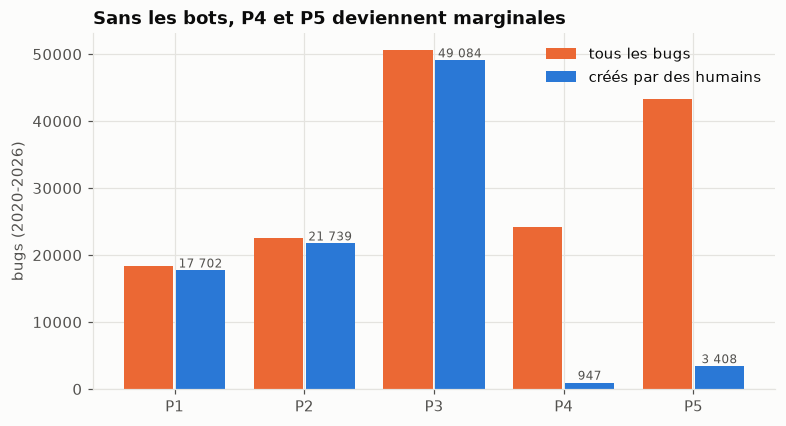

,priority,tous,humains,part_bots_%
0,P1,18344,17702,3.5
1,P2,22512,21739,3.4
2,P3,50588,49084,3.0
3,P4,24197,947,96.1
4,P5,43264,3408,92.1


In [7]:
share = sql(f'''
SELECT priority, COUNT(*) AS tous, SUM({human_sql()}) AS humains FROM bugs
WHERE priority != '--' GROUP BY priority ORDER BY priority
''')
share["part_bots_%"] = (100 * (1 - share.humains / share.tous)).round(1)

fig, ax = plt.subplots()
x = np.arange(len(share))
ax.bar(x - 0.2, share.tous, width=0.38, label="tous les bugs", color=SERIES[1])
ax.bar(x + 0.2, share.humains, width=0.38, label="créés par des humains", color=SERIES[0])
ax.set_xticks(x, share.priority)
ax.set_ylabel("bugs (2020-2026)")
ax.set_title("Sans les bots, P4 et P5 deviennent marginales")
for xi, h in enumerate(share.humains):
    ax.text(xi + 0.2, h, f"{h:,}".replace(",", " "), ha="center", va="bottom", fontsize=8, color="#52514e")
ax.legend()
plt.show()
share

## 3. Classes retenues

Sans les bots, P4 compte moins de 1 000 bugs humains en six ans. P4 et P5 sont fusionnées en une classe **Basse**, ce qui donne quatre niveaux ordonnés correspondant chacun à une action distincte : version en cours, version suivante, backlog, non corrigé. L'échantillon de descriptions a été complété avec l'ensemble des P4/P5 humains, sous-représentés dans le tirage aléatoire.

In [8]:
from jem_prioriser import dataset

labeled = dataset.load_labeled()
print(f"{len(labeled)} bugs humains étiquetés avec description")
labeled["label"].value_counts().sort_index().to_frame("bugs")

21209 bugs humains étiquetés avec description


,bugs
label,
P1,3371
P2,4060
P3,9423
Basse,4355


## 4. Fuites de données

La base contient l'état **actuel** des bugs. Un champ n'est utilisable que s'il est connu **au dépôt**, avant le triage.

In [9]:
raw = sql(f'''
SELECT b.priority, b.severity, b.status, d.n_comments
FROM descriptions d JOIN bugs b ON b.id = d.bug_id
WHERE b.priority != '--' AND {human_sql('b.creator')}
''')
raw["label"] = raw.priority.map(LABEL_OF_PRIORITY)
(pd.crosstab(raw.severity, raw.label, normalize="columns") * 100).round(1)[CLASSES]

label,P1,P2,P3,Basse
severity,,,,
--,21.2,11.5,14.2,8.7
N/A,20.0,19.7,19.1,21.7
S1,1.7,0.0,0.0,0.0
S2,14.3,10.0,0.9,0.4
S3,27.3,45.6,47.6,19.2
S4,6.8,6.7,14.2,45.0
blocker,0.1,0.0,0.0,0.0
critical,0.7,0.2,0.0,0.0
major,0.1,0.0,0.0,0.0


In [10]:
(pd.crosstab(raw.status, raw.label, normalize="columns") * 100).round(1)[CLASSES]

label,P1,P2,P3,Basse
status,,,,
ASSIGNED,0.9,1.6,1.8,1.0
NEW,2.1,14.2,33.9,39.1
REOPENED,0.0,0.4,1.0,0.9
RESOLVED,69.8,69.0,52.9,48.5
UNCONFIRMED,0.1,1.8,5.8,8.4
VERIFIED,27.0,13.0,4.7,2.1


In [11]:
raw.groupby("label").n_comments.median().to_frame("commentaires (médiane)").loc[CLASSES]

,commentaires (médiane)
label,
P1,7.0
P2,7.0
P3,5.0
Basse,5.0


| Champ | Constat | Décision |
|---|---|---|
| `severity` | S4 pour 45 % des « Basse » contre 7 % des P1 ; fixée par le trieur, en même temps que la priorité | exclu |
| `status`, `resolution` | 27 % des P1 sont `VERIFIED` contre 2 % des « Basse » : conséquence de la priorité | exclus |
| nombre de commentaires | plus élevé pour P1/P2, parce qu'ils sont traités en priorité | exclu |
| `keywords` | en partie ajoutés par les trieurs (`regression`, `good-first-bug`…) | exclu par prudence |
| titre, description, produit, composant, type, OS | renseignés au dépôt | conservés |

Risque résiduel accepté : un trieur peut déplacer un bug de composant.

## 5. Dérive temporelle

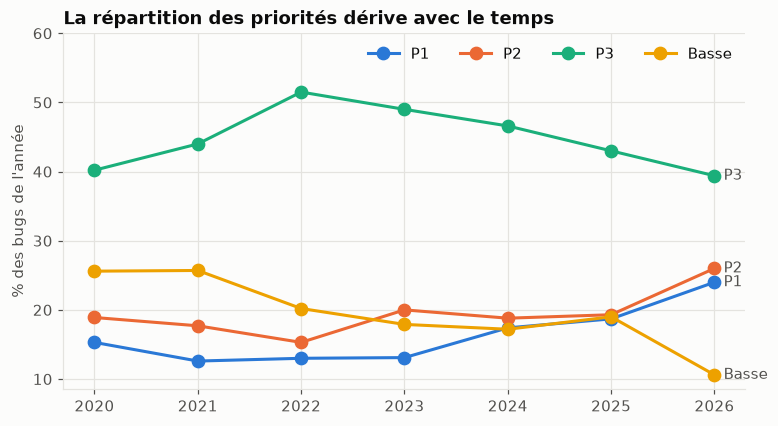

In [12]:
labeled["year"] = labeled.creation_time.dt.year
by_year = (pd.crosstab(labeled.year, labeled.label, normalize="index") * 100).round(1)
fig, ax = plt.subplots()
for c in CLASSES:
    ax.plot(by_year.index, by_year[c], marker="o", label=c, color=CLASS_COLORS[c])
    ax.annotate(c, (by_year.index[-1], by_year[c].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color="#52514e")
ax.set_ylabel("% des bugs de l'année")
ax.set_ylim(top=60)
ax.set_title("La répartition des priorités dérive avec le temps")
ax.legend(ncol=4, loc="upper right")
plt.show()

En 2026, la part de « Basse » chute à 11 % : les bugs récents n'ont pas encore été reclassés en P5, décision souvent prise après plusieurs mois. Un découpage aléatoire mélangerait passé et futur et surestimerait les performances. L'évaluation se fait donc **sur le futur** :

In [13]:
train, val, test = dataset.temporal_split(labeled)
parts = [("train 2020-2024", train), ("validation 2025", val), ("test 2026", test)]
splits = pd.DataFrame({name: part.label.value_counts(normalize=True).round(3) for name, part in parts}).T[CLASSES]
splits["bugs"] = [len(part) for _, part in parts]
splits

label,P1,P2,P3,Basse,bugs
train 2020-2024,0.143,0.182,0.453,0.221,16345
validation 2025,0.187,0.193,0.430,0.190,2649
test 2026,0.240,0.260,0.394,0.106,2215


## 6. Texte

In [14]:
labeled["desc_len"] = labeled.description.str.len()
labeled.groupby("label").agg(
    longueur_mediane=("desc_len", "median"),
    description_vide_pct=("desc_len", lambda s: round(100 * (s == 0).mean(), 1)),
).loc[CLASSES]

,longueur_mediane,description_vide_pct
label,,
P1,408.0,8.1
P2,487.0,7.1
P3,486.0,8.9
Basse,556.0,6.8


Descriptions de quelques centaines de caractères en médiane, vides dans ~8 % des cas, tronquées à 4 000 caractères (certaines contiennent des journaux de plusieurs Mo). La longueur ne distingue pas les classes : le signal devra venir du vocabulaire et du composant.

## Décisions

| Décision | Justification | Implémentation |
|---|---|---|
| Bugzilla Mozilla, depuis 2020 | API ouverte, volume, backlog non trié réel | `collect.py` |
| Exclusion de 13 comptes bots | 96 % des P4 et 92 % des P5 | `cleaning.py` |
| 4 classes : P1, P2, P3, Basse | P4 quasi inutilisée par les humains | `cleaning.py` |
| Exclusion de severity, status, resolution, keywords, commentaires | fuites : fixés pendant ou après le triage | `dataset.py` |
| Découpage chronologique | dérive de la répartition ; on prédit le futur | `dataset.temporal_split` |
| Bugs de bots conservés à part | jeu « hors distribution » naturel pour l'évaluation | `dataset.load_bot_bugs` |

In [15]:
db.close()